# Electric Vehicle Charging Optimization Using Reinforcement Learning
## Part 2: PPO Implementation

This notebook follows the submitted Part 1 design:
- PPO algorithm
- Custom Gymnasium environment
- State: SOC, electricity price, current time, remaining time, target SOC
- Continuous charging action
- Reward based on charging cost and target-SOC achievement
- Immediate-charging baseline
- Rule-based low-price baseline
- Evaluation on unseen scenarios


In [1]:
!pip install -q gymnasium stable-baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 3.6 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.callbacks import BaseCallback

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. Custom EV Charging Environment

In [3]:

class EVChargingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(
        self,
        battery_capacity=60.0,
        max_charging_power=7.2,
        charging_efficiency=0.90,
        episode_length=13,
        shortfall_penalty_weight=50.0,
        overcharge_penalty_weight=2.0
    ):
        super().__init__()

        self.battery_capacity = float(battery_capacity)
        self.max_charging_power = float(max_charging_power)
        self.charging_efficiency = float(charging_efficiency)
        self.episode_length = int(episode_length)
        self.shortfall_penalty_weight = float(shortfall_penalty_weight)
        self.overcharge_penalty_weight = float(overcharge_penalty_weight)

        self.action_space = spaces.Box(
            low=np.array([-1.0], dtype=np.float32),
            high=np.array([1.0], dtype=np.float32),
            dtype=np.float32
        )

        self.observation_space = spaces.Box(
            low=np.zeros(5, dtype=np.float32),
            high=np.ones(5, dtype=np.float32),
            dtype=np.float32
        )

        self.current_step = 0
        self.soc = 0.0
        self.target_soc = 0.0
        self.total_cost = 0.0
        self.price_profile = None
        self.history = []

    def _generate_price_profile(self):
        base = np.array(
            [0.30, 0.28, 0.25, 0.22, 0.18, 0.14, 0.11,
             0.09, 0.08, 0.10, 0.13, 0.17, 0.21],
            dtype=np.float32
        )

        if self.episode_length != len(base):
            x_old = np.linspace(0, 1, len(base))
            x_new = np.linspace(0, 1, self.episode_length)
            base = np.interp(x_new, x_old, base).astype(np.float32)

        noise = self.np_random.normal(0.0, 0.015, size=self.episode_length)
        return np.clip(base + noise, 0.05, None).astype(np.float32)

    def _get_obs(self):
        current_price = float(self.price_profile[self.current_step])
        max_price = max(float(np.max(self.price_profile)), 1e-6)

        normalized_price = current_price / max_price
        normalized_time = self.current_step / max(self.episode_length - 1, 1)
        remaining = (self.episode_length - 1) - self.current_step
        normalized_remaining = remaining / max(self.episode_length - 1, 1)

        return np.array([
            self.soc,
            normalized_price,
            normalized_time,
            normalized_remaining,
            self.target_soc
        ], dtype=np.float32)

    def _action_to_power(self, action):
        normalized = (float(action[0]) + 1.0) / 2.0
        normalized = np.clip(normalized, 0.0, 1.0)
        return normalized * self.max_charging_power

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.current_step = 0
        self.soc = float(self.np_random.uniform(0.20, 0.60))
        self.target_soc = float(self.np_random.uniform(0.70, 0.90))
        self.target_soc = max(self.target_soc, min(self.soc + 0.10, 0.95))

        self.price_profile = self._generate_price_profile()
        self.total_cost = 0.0
        self.history = []

        info = {
            "initial_soc": self.soc,
            "target_soc": self.target_soc,
            "price": float(self.price_profile[0]),
            "total_cost": self.total_cost
        }

        return self._get_obs(), info

    def step(self, action):
        charging_power = self._action_to_power(action)
        price = float(self.price_profile[self.current_step])

        energy_requested = charging_power * self.charging_efficiency
        max_energy_allowed = max(
            0.0,
            (1.0 - self.soc) * self.battery_capacity
        )
        energy_added = min(energy_requested, max_energy_allowed)

        soc_before = self.soc
        self.soc += energy_added / self.battery_capacity
        self.soc = float(np.clip(self.soc, 0.0, 1.0))

        step_cost = price * energy_added
        self.total_cost += step_cost

        reward = -step_cost

        self.history.append({
            "step": self.current_step,
            "price": price,
            "soc_before": soc_before,
            "charging_power": charging_power,
            "energy_added": energy_added,
            "soc": self.soc,
            "step_cost": step_cost,
            "total_cost": self.total_cost
        })

        self.current_step += 1
        terminated = self.current_step >= self.episode_length
        truncated = False

        if terminated:
            shortfall = max(self.target_soc - self.soc, 0.0)
            excess = max(self.soc - self.target_soc, 0.0)

            reward -= self.shortfall_penalty_weight * shortfall
            reward -= self.overcharge_penalty_weight * excess

            obs = np.array([
                self.soc, 0.0, 1.0, 0.0, self.target_soc
            ], dtype=np.float32)
        else:
            obs = self._get_obs()

        info = {
            "soc": self.soc,
            "target_soc": self.target_soc,
            "total_cost": self.total_cost,
            "charging_power": charging_power
        }

        return obs, float(reward), terminated, truncated, info

    def render(self):
        print(
            f"Step={self.current_step}, "
            f"SOC={self.soc:.2%}, "
            f"Target={self.target_soc:.2%}, "
            f"Cost=${self.total_cost:.2f}"
        )


## 2. Validate the Environment

In [4]:
env = EVChargingEnv()
check_env(env, warn=True)
print("Environment validation completed.")


Environment validation completed.


## 3. Test One Episode with Random Actions

In [5]:
env = EVChargingEnv()
obs, info = env.reset(seed=SEED)

done = False
episode_reward = 0.0

while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    episode_reward += reward
    done = terminated or truncated

random_df = pd.DataFrame(env.history)

print(f"Final SOC: {env.soc:.2%}")
print(f"Target SOC: {env.target_soc:.2%}")
print(f"Total Cost: ${env.total_cost:.2f}")
print(f"Cumulative Reward: {episode_reward:.2f}")

random_df


Final SOC: 100.00%
Target SOC: 78.78%
Total Cost: $4.18
Cumulative Reward: -4.60


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,step,price,soc_before,charging_power,energy_added,soc,step_cost,total_cost
0,0,0.311257,0.509582,0.420445,0.378401,0.515889,0.117780,0.117780
1,1,0.294108,0.515889,2.561946,2.305752,0.554318,0.678141,0.795921
2,2,0.220734,0.554318,1.272020,1.144818,0.573399,0.252701,1.048622
3,3,0.200467,0.573399,0.998820,0.898938,0.588381,0.180208,1.228829
4,4,0.181918,0.588381,3.256897,2.931208,0.637234,0.533238,1.762068
5,5,0.135256,0.637234,6.361887,5.725698,0.732663,0.774437,2.536505
6,6,0.109748,0.732663,1.013255,0.911930,0.747861,0.100082,2.636587
7,7,0.077204,0.747861,6.928309,6.235478,0.851786,0.481406,3.117993
8,8,0.093191,0.851786,1.641649,1.477484,0.876411,0.137688,3.255681
9,9,0.111667,0.876411,6.358996,5.723096,0.971796,0.639080,3.894762


## 4. Track PPO Training Convergence

In [6]:
class RewardTrackingCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.episode_rewards = []
        self.current_rewards = None

    def _on_training_start(self):
        self.current_rewards = np.zeros(
            self.training_env.num_envs,
            dtype=np.float64
        )

    def _on_step(self):
        rewards = np.asarray(self.locals["rewards"])
        dones = np.asarray(self.locals["dones"])

        self.current_rewards += rewards

        for i, done in enumerate(dones):
            if done:
                self.episode_rewards.append(
                    float(self.current_rewards[i])
                )
                self.current_rewards[i] = 0.0

        return True


## 5. Train PPO

In [26]:
train_env = EVChargingEnv()
reward_callback = RewardTrackingCallback()

model = PPO(
    "MlpPolicy",
    train_env,
    learning_rate=3e-4,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.20,
    n_steps=512,
    batch_size=64,
    n_epochs=10,
    verbose=1,
    seed=SEED
)

model.learn(
    total_timesteps=10000,
    callback=reward_callback
)

print("PPO training completed.")


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 13       |
|    ep_rew_mean     | -7.11    |
| time/              |          |
|    fps             | 1437     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 512      |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 13          |
|    ep_rew_mean          | -6.87       |
| time/                   |             |
|    fps                  | 895         |
|    iterations           | 2           |
|    time_elapsed         | 1           |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.004707232 |
|    clip_fraction        | 0.0316      |
|    clip_range           | 0.2         |
|    entropy_loss   

## 6. Training Convergence Plot

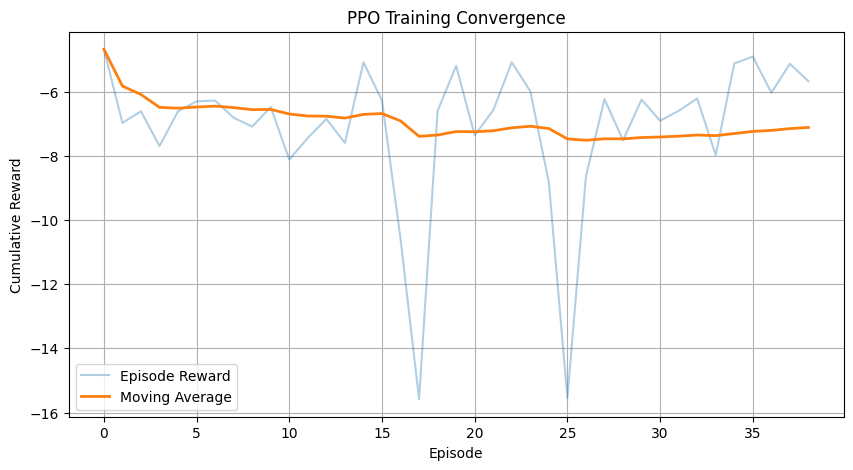

In [8]:
rewards = np.array(reward_callback.episode_rewards)

if len(rewards) > 0:
    moving_average = (
        pd.Series(rewards)
        .rolling(window=min(100, len(rewards)), min_periods=1)
        .mean()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(rewards, alpha=0.35, label="Episode Reward")
    plt.plot(moving_average, linewidth=2, label="Moving Average")
    plt.xlabel("Episode")
    plt.ylabel("Cumulative Reward")
    plt.title("PPO Training Convergence")
    plt.legend()
    plt.grid(True)
    plt.show()


## 7. Fixed Scenario Helper for Fair Comparison

In [9]:
def build_fixed_env(initial_soc, target_soc, price_profile):
    env = EVChargingEnv(episode_length=len(price_profile))
    obs, _ = env.reset()

    env.soc = float(initial_soc)
    env.target_soc = float(target_soc)
    env.price_profile = np.array(price_profile, dtype=np.float32)
    env.total_cost = 0.0
    env.current_step = 0
    env.history = []

    return env, env._get_obs()


## 8. PPO Evaluation Function

In [10]:
def run_ppo(model, initial_soc, target_soc, price_profile):
    env, obs = build_fixed_env(initial_soc, target_soc, price_profile)

    done = False
    cumulative_reward = 0.0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)

        cumulative_reward += reward
        done = terminated or truncated

    result = {
        "strategy": "PPO",
        "initial_soc": initial_soc,
        "target_soc": target_soc,
        "final_soc": env.soc,
        "total_cost": env.total_cost,
        "success": env.soc >= target_soc,
        "cumulative_reward": cumulative_reward,
        "soc_shortfall": max(target_soc - env.soc, 0.0),
        "excess_soc": max(env.soc - target_soc, 0.0)
    }

    return result, pd.DataFrame(env.history)


## 9. Baseline 1: Immediate Charging

In [11]:
def run_immediate_charging(initial_soc, target_soc, price_profile):
    env, obs = build_fixed_env(initial_soc, target_soc, price_profile)

    done = False
    cumulative_reward = 0.0

    while not done:
        if env.soc < env.target_soc:
            action = np.array([1.0], dtype=np.float32)
        else:
            action = np.array([-1.0], dtype=np.float32)

        obs, reward, terminated, truncated, info = env.step(action)

        cumulative_reward += reward
        done = terminated or truncated

    result = {
        "strategy": "Immediate Charging",
        "initial_soc": initial_soc,
        "target_soc": target_soc,
        "final_soc": env.soc,
        "total_cost": env.total_cost,
        "success": env.soc >= target_soc,
        "cumulative_reward": cumulative_reward,
        "soc_shortfall": max(target_soc - env.soc, 0.0),
        "excess_soc": max(env.soc - target_soc, 0.0)
    }

    return result, pd.DataFrame(env.history)


## 10. Baseline 2: Rule-Based Low-Price Charging

In [12]:
def run_rule_based_charging(initial_soc, target_soc, price_profile):
    env, obs = build_fixed_env(initial_soc, target_soc, price_profile)

    threshold = float(np.median(price_profile))

    done = False
    cumulative_reward = 0.0

    while not done:
        price = float(env.price_profile[env.current_step])
        remaining_steps = env.episode_length - env.current_step

        energy_needed = max(
            0.0,
            (env.target_soc - env.soc) * env.battery_capacity
        )

        energy_per_full_step = (
            env.max_charging_power * env.charging_efficiency
        )

        steps_needed = int(
            np.ceil(energy_needed / energy_per_full_step)
        ) if energy_per_full_step > 0 else remaining_steps

        if env.soc >= env.target_soc:
            action = np.array([-1.0], dtype=np.float32)

        elif price <= threshold:
            action = np.array([1.0], dtype=np.float32)

        elif remaining_steps <= steps_needed:
            action = np.array([1.0], dtype=np.float32)

        else:
            action = np.array([-1.0], dtype=np.float32)

        obs, reward, terminated, truncated, info = env.step(action)

        cumulative_reward += reward
        done = terminated or truncated

    result = {
        "strategy": "Rule-Based Charging",
        "initial_soc": initial_soc,
        "target_soc": target_soc,
        "final_soc": env.soc,
        "total_cost": env.total_cost,
        "success": env.soc >= target_soc,
        "cumulative_reward": cumulative_reward,
        "soc_shortfall": max(target_soc - env.soc, 0.0),
        "excess_soc": max(env.soc - target_soc, 0.0)
    }

    return result, pd.DataFrame(env.history)


## 11. Generate Unseen Test Scenarios

In [13]:
def generate_test_scenarios(n_scenarios=100, seed=123):
    rng = np.random.default_rng(seed)

    base_price = np.array(
        [0.30, 0.28, 0.25, 0.22, 0.18, 0.14, 0.11,
         0.09, 0.08, 0.10, 0.13, 0.17, 0.21],
        dtype=float
    )

    scenarios = []

    for i in range(n_scenarios):
        initial_soc = float(rng.uniform(0.20, 0.60))
        target_soc = float(rng.uniform(0.70, 0.90))

        price_profile = np.clip(
            base_price + rng.normal(0.0, 0.015, len(base_price)),
            0.05,
            None
        )

        scenarios.append({
            "scenario_id": i,
            "initial_soc": initial_soc,
            "target_soc": target_soc,
            "price_profile": price_profile
        })

    return scenarios


test_scenarios = generate_test_scenarios()
print("Test scenarios:", len(test_scenarios))


Test scenarios: 100


## 12. Evaluate All Three Strategies

In [14]:
all_results = []

for scenario in test_scenarios:
    sid = scenario["scenario_id"]
    initial_soc = scenario["initial_soc"]
    target_soc = scenario["target_soc"]
    prices = scenario["price_profile"]

    for runner in [
        lambda: run_ppo(model, initial_soc, target_soc, prices),
        lambda: run_immediate_charging(initial_soc, target_soc, prices),
        lambda: run_rule_based_charging(initial_soc, target_soc, prices)
    ]:
        result, _ = runner()
        result["scenario_id"] = sid
        all_results.append(result)

results_df = pd.DataFrame(all_results)
results_df.head()


,strategy,initial_soc,target_soc,final_soc,total_cost,success,cumulative_reward,soc_shortfall,excess_soc,scenario_id
0,PPO,0.472941,0.710764,1.000000,5.635836,True,-6.214308,0.0,0.289236,0
1,Immediate Charging,0.472941,0.710764,0.796941,5.611887,True,-5.784240,0.0,0.086177,0
2,Rule-Based Charging,0.472941,0.710764,0.796941,2.193768,True,-2.366122,0.0,0.086177,0
3,PPO,0.451976,0.885481,1.000000,5.826716,True,-6.055753,0.0,0.114519,1
4,Immediate Charging,0.451976,0.885481,0.991976,7.774683,True,-7.987673,0.0,0.106495,1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 13. Evaluation Metrics

### Total Charging Cost

\[
TotalCost =
\sum_{t=1}^{T}
Price_t \times Energy_t
\]

### Target SOC Success

\[
FinalSOC \geq TargetSOC
\]

### Target SOC Success Rate

\[
SuccessRate =
\frac{SuccessfulEpisodes}{TotalTestEpisodes}
\times 100
\]

### Cost Savings

\[
CostSavings =
\frac{BaselineCost - PPOCost}{BaselineCost}
\times 100
\]


In [15]:
summary_df = (
    results_df
    .groupby("strategy")
    .agg(
        average_total_cost=("total_cost", "mean"),
        average_final_soc=("final_soc", "mean"),
        success_rate=("success", "mean"),
        average_cumulative_reward=("cumulative_reward", "mean"),
        average_soc_shortfall=("soc_shortfall", "mean"),
        average_excess_soc=("excess_soc", "mean")
    )
    .reset_index()
)

summary_df["success_rate"] *= 100
summary_df


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,strategy,average_total_cost,average_final_soc,success_rate,average_cumulative_reward,average_soc_shortfall,average_excess_soc
0,Immediate Charging,6.670469,0.84523,100.0,-6.778600,0.0,0.054065
1,PPO,6.157992,0.99743,100.0,-6.570523,0.0,0.206265
2,Rule-Based Charging,2.895716,0.84523,100.0,-3.003846,0.0,0.054065


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 14. PPO Cost Savings Compared with Baselines

In [16]:
mean_costs = results_df.groupby("strategy")["total_cost"].mean()

ppo_cost = mean_costs["PPO"]

cost_savings = pd.DataFrame({
    "Baseline": ["Immediate Charging", "Rule-Based Charging"],
    "Cost Savings (%)": [
        (mean_costs["Immediate Charging"] - ppo_cost)
        / mean_costs["Immediate Charging"] * 100,

        (mean_costs["Rule-Based Charging"] - ppo_cost)
        / mean_costs["Rule-Based Charging"] * 100
    ]
})

cost_savings


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Baseline,Cost Savings (%)
0,Immediate Charging,7.682777
1,Rule-Based Charging,-112.658699


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 15. Average Charging Cost Comparison

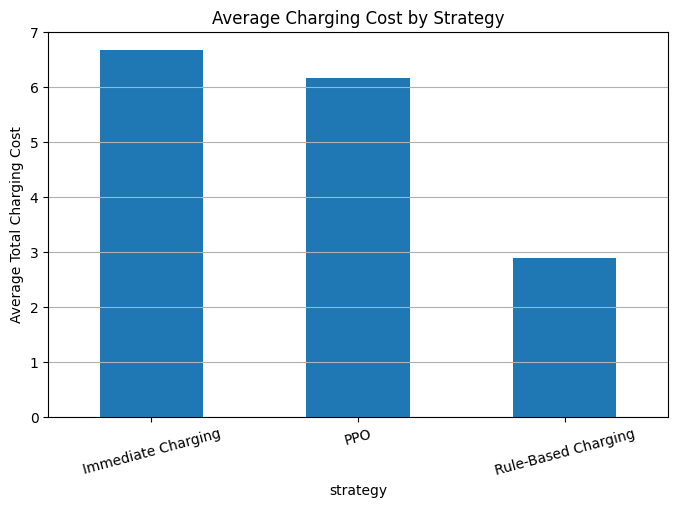

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
avg_cost = results_df.groupby("strategy")["total_cost"].mean()

plt.figure(figsize=(8, 5))
avg_cost.plot(kind="bar")
plt.ylabel("Average Total Charging Cost")
plt.title("Average Charging Cost by Strategy")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()


## 16. Target SOC Success Rate Comparison

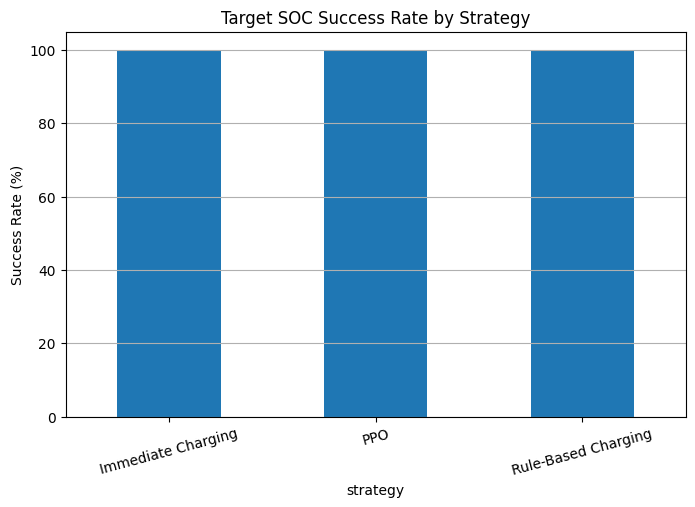

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [18]:
success_rate = (
    results_df.groupby("strategy")["success"].mean() * 100
)

plt.figure(figsize=(8, 5))
success_rate.plot(kind="bar")
plt.ylabel("Success Rate (%)")
plt.title("Target SOC Success Rate by Strategy")
plt.xticks(rotation=15)
plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()


## 17. Visualize Policy Behavior on One Unseen Scenario

In [19]:
example = test_scenarios[0]

initial_soc = example["initial_soc"]
target_soc = example["target_soc"]
prices = example["price_profile"]

ppo_result, ppo_history = run_ppo(
    model, initial_soc, target_soc, prices
)

immediate_result, immediate_history = run_immediate_charging(
    initial_soc, target_soc, prices
)

rule_result, rule_history = run_rule_based_charging(
    initial_soc, target_soc, prices
)

print("PPO:", ppo_result)
print("Immediate:", immediate_result)
print("Rule-based:", rule_result)


PPO: {'strategy': 'PPO', 'initial_soc': 0.4729407452992574, 'target_soc': 0.7107642037604445, 'final_soc': 1.0, 'total_cost': np.float64(5.635836133471209), 'success': True, 'cumulative_reward': -6.21430772595032, 'soc_shortfall': 0.0, 'excess_soc': 0.28923579623955553}
Immediate: {'strategy': 'Immediate Charging', 'initial_soc': 0.4729407452992574, 'target_soc': 0.7107642037604445, 'final_soc': 0.7969407452992574, 'total_cost': np.float64(5.611887001991272), 'success': True, 'cumulative_reward': -5.784240085068898, 'soc_shortfall': 0.0, 'excess_soc': 0.08617654153881293}
Rule-based: {'strategy': 'Rule-Based Charging', 'initial_soc': 0.4729407452992574, 'target_soc': 0.7107642037604445, 'final_soc': 0.7969407452992574, 'total_cost': np.float64(2.1937684267759323), 'success': True, 'cumulative_reward': -2.366121509853558, 'soc_shortfall': 0.0, 'excess_soc': 0.08617654153881293}


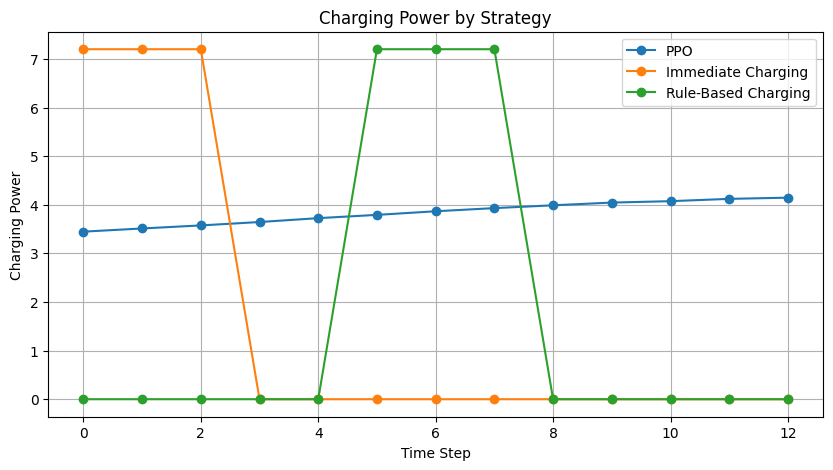

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(
    ppo_history["step"],
    ppo_history["charging_power"],
    marker="o",
    label="PPO"
)
plt.plot(
    immediate_history["step"],
    immediate_history["charging_power"],
    marker="o",
    label="Immediate Charging"
)
plt.plot(
    rule_history["step"],
    rule_history["charging_power"],
    marker="o",
    label="Rule-Based Charging"
)

plt.xlabel("Time Step")
plt.ylabel("Charging Power")
plt.title("Charging Power by Strategy")
plt.legend()
plt.grid(True)
plt.show()


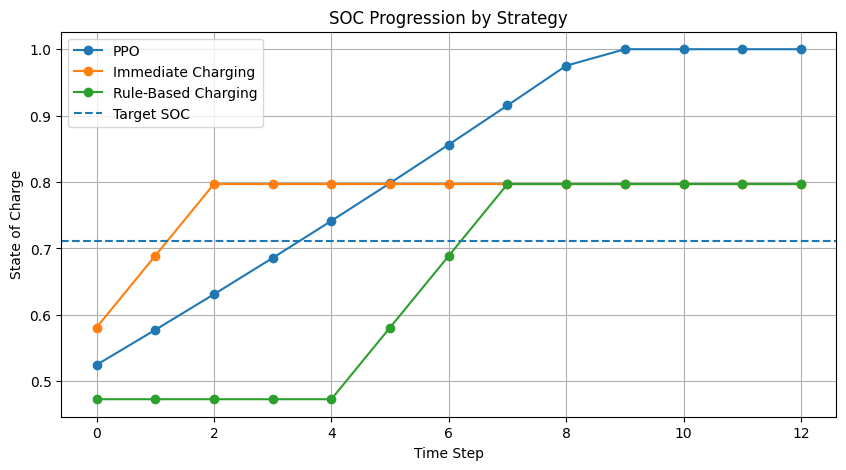

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(
    ppo_history["step"],
    ppo_history["soc"],
    marker="o",
    label="PPO"
)
plt.plot(
    immediate_history["step"],
    immediate_history["soc"],
    marker="o",
    label="Immediate Charging"
)
plt.plot(
    rule_history["step"],
    rule_history["soc"],
    marker="o",
    label="Rule-Based Charging"
)

plt.axhline(target_soc, linestyle="--", label="Target SOC")

plt.xlabel("Time Step")
plt.ylabel("State of Charge")
plt.title("SOC Progression by Strategy")
plt.legend()
plt.grid(True)
plt.show()


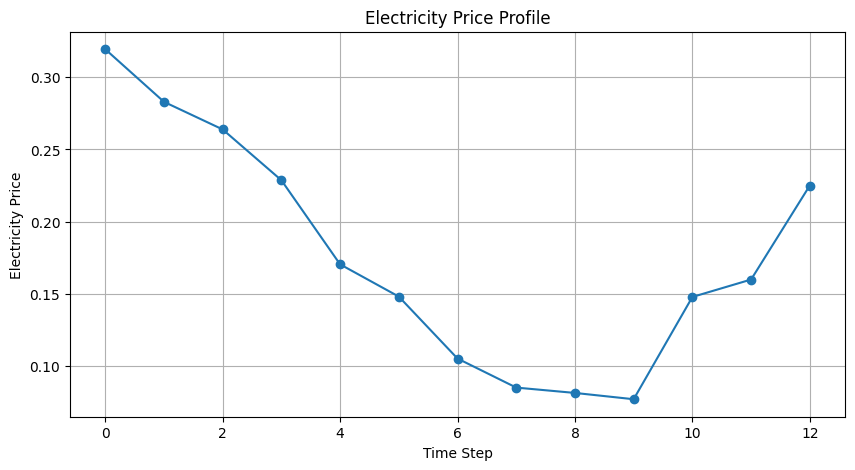

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(
    ppo_history["step"],
    ppo_history["price"],
    marker="o"
)
plt.xlabel("Time Step")
plt.ylabel("Electricity Price")
plt.title("Electricity Price Profile")
plt.grid(True)
plt.show()


## 18. Final Results Table

In [23]:
final_table = summary_df.copy()

final_table["average_total_cost"] = final_table["average_total_cost"].round(3)
final_table["average_final_soc"] = (final_table["average_final_soc"] * 100).round(2)
final_table["success_rate"] = final_table["success_rate"].round(2)
final_table["average_cumulative_reward"] = final_table["average_cumulative_reward"].round(3)
final_table["average_soc_shortfall"] = (final_table["average_soc_shortfall"] * 100).round(2)
final_table["average_excess_soc"] = (final_table["average_excess_soc"] * 100).round(2)

final_table


,strategy,average_total_cost,average_final_soc,success_rate,average_cumulative_reward,average_soc_shortfall,average_excess_soc
0,Immediate Charging,6.670,84.52,100.0,-6.779,0.0,5.41
1,PPO,6.158,99.74,100.0,-6.571,0.0,20.63
2,Rule-Based Charging,2.896,84.52,100.0,-3.004,0.0,5.41


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 19. Save Results

In [24]:
results_df.to_csv("ev_charging_all_results.csv", index=False)
summary_df.to_csv("ev_charging_summary.csv", index=False)
cost_savings.to_csv("ev_charging_cost_savings.csv", index=False)

print("CSV files saved.")


CSV files saved.


## 20. How to Interpret Part 2

The project hypothesis is supported if the trained PPO agent:

- reaches the target SOC consistently,
- reduces average charging cost relative to immediate charging,
- shows improving and stabilizing training reward,
- shifts charging toward lower-price periods,
- and still charges when departure is approaching and SOC is insufficient.

If PPO does not outperform a baseline, report that result and discuss possible reasons such as insufficient training, reward design, hyperparameter selection, or limited state information.
